# Phase 2 – Exploratory Data Analysis (EDA)

Name: Anusha VK

Tools Used: Python, Pandas, Numpy, Matplotlib

## NexaTel Customer Churn Analysis

## Objective
The objective of this phase is to explore the cleaned NexaTel data and find the patterns and factors that are linked to customer churn, using charts and short observations.

In [55]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

customers = pd.read_csv("customers_cleaned.csv", parse_dates=["date_of_birth", "acquisition_date", "churn_date"])
subscriptions = pd.read_csv("subscriptions_cleaned.csv", parse_dates=["start_date", "end_date"])
complaints = pd.read_csv("complaints_cleaned.csv", parse_dates=["complaint_date", "resolution_date"])
usage_data = pd.read_csv("usage_data_cleaned.csv")
network_quality = pd.read_csv("network_quality_cleaned.csv")
retention = pd.read_csv("retention_campaigns_cleaned.csv", parse_dates=["contact_date"])
states = pd.read_csv("states_cleaned.csv")
cities = pd.read_csv("cities_cleaned.csv")
plans = pd.read_csv("plans_cleaned.csv")

for name, df in [("customers", customers), ("subscriptions", subscriptions), ("complaints", complaints),
                 ("usage_data", usage_data), ("network_quality", network_quality),
                 ("retention", retention), ("states", states), ("cities", cities), ("plans", plans)]:
    print(name, df.shape)

print(customers["customer_status"].value_counts())

customers (19000, 26)
subscriptions (20523, 8)
complaints (16584, 7)
usage_data (57000, 6)
network_quality (57000, 8)
retention (6475, 8)
states (36, 4)
cities (68, 8)
plans (25, 10)
customer_status
Active     15494
Churned     3506
Name: count, dtype: int64


## Chart 1 – Overall Churn Rate

Total customers: 19000
Churned customers: 3506
Churn rate: 18.45 %


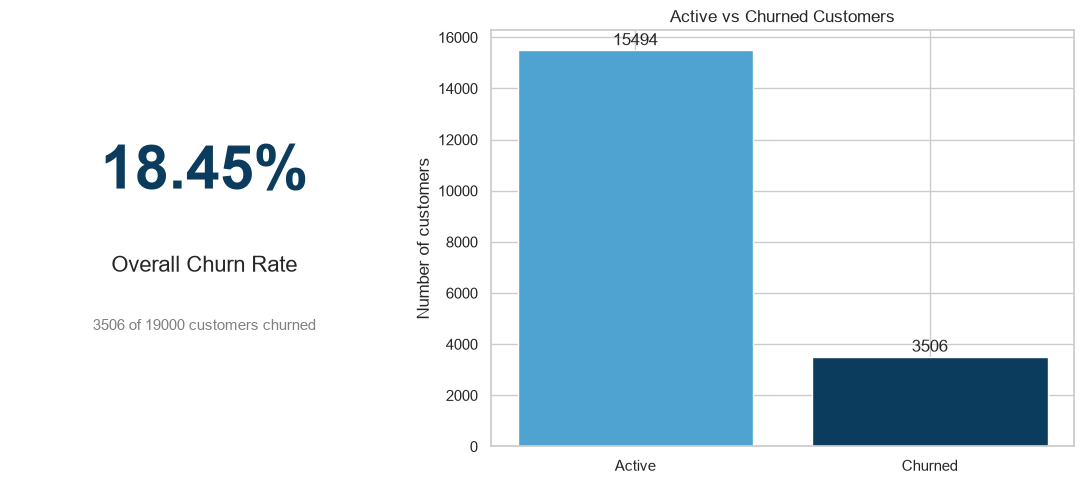

In [56]:
status_counts = customers["customer_status"].value_counts()
total_customers = len(customers)
churned_customers = status_counts["Churned"]
churn_rate = churned_customers / total_customers * 100

print("Total customers:", total_customers)
print("Churned customers:", churned_customers)
print("Churn rate:", round(churn_rate, 2), "%")

fig, axes = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [1, 1.5]})

# left side: KPI card
axes[0].axis("off")
axes[0].text(0.5, 0.62, str(round(churn_rate, 2)) + "%", fontsize=44, fontweight="bold", color="#0B3C5D", ha="center")
axes[0].text(0.5, 0.42, "Overall Churn Rate", fontsize=16, ha="center")
axes[0].text(0.5, 0.28, str(churned_customers) + " of " + str(total_customers) + " customers churned", fontsize=11, ha="center", color="gray")

# right side: bar chart (Active = light, Churned = dark)
axes[1].bar(status_counts.index, status_counts.values, color=["#4FA3D1","#0B3C5D"])
for i in range(len(status_counts)):
    axes[1].text(i, status_counts.values[i] + 200, str(status_counts.values[i]), ha="center", fontsize=12)
axes[1].set_title("Active vs Churned Customers")
axes[1].set_ylabel("Number of customers")

plt.tight_layout()
plt.savefig("chart1_overall_churn.png", dpi=150)
plt.show()

### Observation
Out of 19,000 customers, 3,506 have churned, which gives an overall churn rate of 18.45%. The remaining 15,494 customers are still active. This figure is the share of all customers who have ever left, so it is not directly comparable with the monthly churn target of 2.1% in the project document. Monthly churn is calculated in Phase 3. Nearly one in five customers has already been lost, which shows that churn is a significant business problem.

## Chart 2 – Churn by Billing Cycle

customer_status  Active  Churned  total  churn_rate_%
billing_cycle                                        
Annual             4689      362   5051          7.17
Monthly           10805     3144  13949         22.54


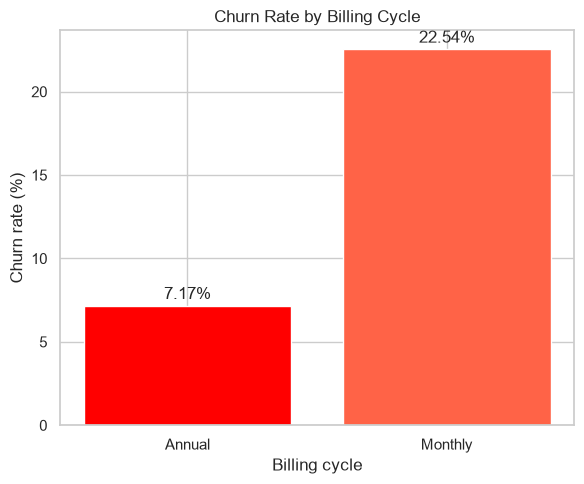

In [57]:
# add the billing cycle of each customer's plan
data = customers.merge(plans[["plan_id", "billing_cycle"]], on="plan_id", how="left")

summary = pd.crosstab(data["billing_cycle"], data["customer_status"])
summary["total"] = summary["Active"] + summary["Churned"]
summary["churn_rate_%"] = (summary["Churned"] / summary["total"] * 100).round(2)
print(summary)

plt.figure(figsize=(6, 5))
plt.bar(summary.index, summary["churn_rate_%"], color=["red", "tomato"])
for i in range(len(summary)):
    plt.text(i, summary["churn_rate_%"].values[i] + 0.4, str(summary["churn_rate_%"].values[i]) + "%", ha="center", fontsize=12)
plt.title("Churn Rate by Billing Cycle")
plt.xlabel("Billing cycle")
plt.ylabel("Churn rate (%)")
plt.tight_layout()
plt.savefig("chart2_churn_by_billing_cycle.png", dpi=150)
plt.show()

### Observation

Customers on monthly plans churn much more than customers on annual plans: 22.54% compared with 7.17%, which is about three times higher. Monthly customers have no long-term commitment and can leave at any time, while annual customers have already paid for a full year. This suggests that moving monthly customers to annual plans, for example with a discount, could help reduce churn.

## Chart 3 – Churn by Tenure Band

customer_status  Active  Churned  total  churn_rate_%
tenure_band                                          
0-3m                188      561    749         74.90
3-12m               690      756   1446         52.28
1-3y               1810     1026   2836         36.18
3y+               12806     1163  13969          8.33


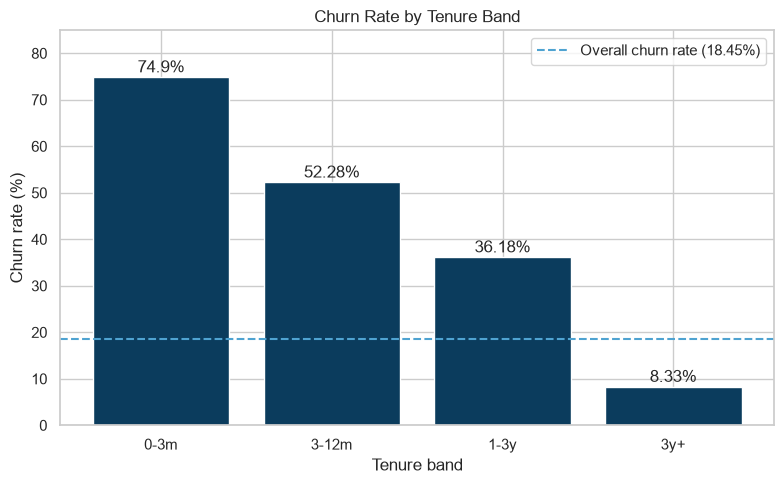

In [58]:
# group customers into tenure bands
customers["tenure_band"] = pd.cut(customers["tenure_months"],
                                  bins=[-1, 3, 12, 36, 1000],
                                  labels=["0-3m", "3-12m", "1-3y", "3y+"])

summary3 = pd.crosstab(customers["tenure_band"], customers["customer_status"])
summary3["total"] = summary3["Active"] + summary3["Churned"]
summary3["churn_rate_%"] = (summary3["Churned"] / summary3["total"] * 100).round(2)
print(summary3)

plt.figure(figsize=(8, 5))
plt.bar(summary3.index.astype(str), summary3["churn_rate_%"], color="#0B3C5D")
for i in range(len(summary3)):
    plt.text(i, summary3["churn_rate_%"].values[i] + 1, str(summary3["churn_rate_%"].values[i]) + "%", ha="center", fontsize=12)
plt.axhline(churn_rate, color="#4FA3D1", linestyle="--", label="Overall churn rate (" + str(round(churn_rate, 2)) + "%)")
plt.ylim(0, summary3["churn_rate_%"].max() + 10)
plt.title("Churn Rate by Tenure Band")
plt.xlabel("Tenure band")
plt.ylabel("Churn rate (%)")
plt.legend()
plt.tight_layout()
plt.savefig("chart3_churn_by_tenure.png", dpi=150)
plt.show()

### Observation

Churn falls sharply as tenure increases: 74.90% of customers in their first 3 months have churned, compared with 52.28% for 3–12 months, 36.18% for 1–3 years and only 8.33% for customers with more than 3 years. This means most customers leave early in their lifecycle, so the first year is the most critical period for retention. Offers, onboarding support and early follow-ups for new customers could reduce churn. Note that for churned customers the tenure is the time until they left, so the early bands naturally contain many churned customers.

## Chart 4 – Churn by Number of Unresolved Complaints

customer_status  Active  Churned  total  churn_rate_%
complaint_group                                      
0                 10986     1956  12942         15.11
1                  3781     1153   4934         23.37
2                   650      325    975         33.33
3+                   77       72    149         48.32


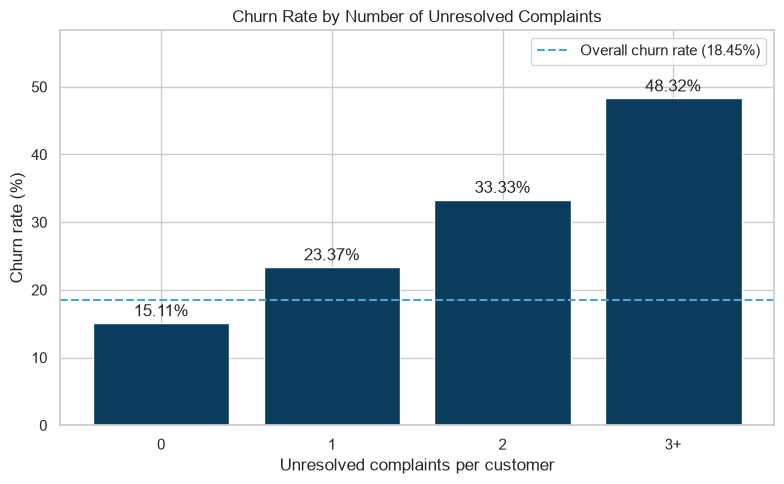

In [59]:
# count unresolved complaints for each customer
unresolved = complaints[complaints["status"] == "Unresolved"]
unresolved_count = unresolved.groupby("customer_id").size().reset_index(name="unresolved_complaints")

data = customers.merge(unresolved_count, on="customer_id", how="left")
data["unresolved_complaints"] = data["unresolved_complaints"].fillna(0).astype(int)

# group 3 or more together
data["complaint_group"] = data["unresolved_complaints"].clip(upper=3).astype(str)
data["complaint_group"] = data["complaint_group"].replace({"3": "3+"})

summary4 = pd.crosstab(data["complaint_group"], data["customer_status"])
summary4["total"] = summary4["Active"] + summary4["Churned"]
summary4["churn_rate_%"] = (summary4["Churned"] / summary4["total"] * 100).round(2)
print(summary4)

plt.figure(figsize=(8, 5))
plt.bar(summary4.index, summary4["churn_rate_%"], color="#0B3C5D")
for i in range(len(summary4)):
    plt.text(i, summary4["churn_rate_%"].values[i] + 1, str(summary4["churn_rate_%"].values[i]) + "%", ha="center", fontsize=12)
plt.axhline(churn_rate, color="#4FA3D1", linestyle="--", label="Overall churn rate (" + str(round(churn_rate, 2)) + "%)")
plt.ylim(0, summary4["churn_rate_%"].max() + 10)
plt.title("Churn Rate by Number of Unresolved Complaints")
plt.xlabel("Unresolved complaints per customer")
plt.ylabel("Churn rate (%)")
plt.legend()
plt.tight_layout()
plt.savefig("chart4_churn_by_complaints.png", dpi=150)
plt.show()

### Observation
Churn increases steadily with the number of unresolved complaints: 15.11% for customers with none, 23.37% with one, 33.33% with two and 48.32% with three or more. Customers with three or more unresolved complaints churn at more than three times the rate of customers with none. Only 149 customers fall into the 3+ group, so that figure should be read with some caution. Even so, the pattern clearly suggests that unresolved complaints push customers to leave, and that resolving complaints quickly, especially for customers with repeat complaints, should be a retention priority.

## Chart 5 – Churn by Customer Segment

customer_status   Active  Churned  total  churn_rate_%
customer_segment                                      
Mass                2150      782   2932         26.67
Value               4921     1275   6196         20.58
Premium             7199     1283   8482         15.13
Enterprise          1224      166   1390         11.94


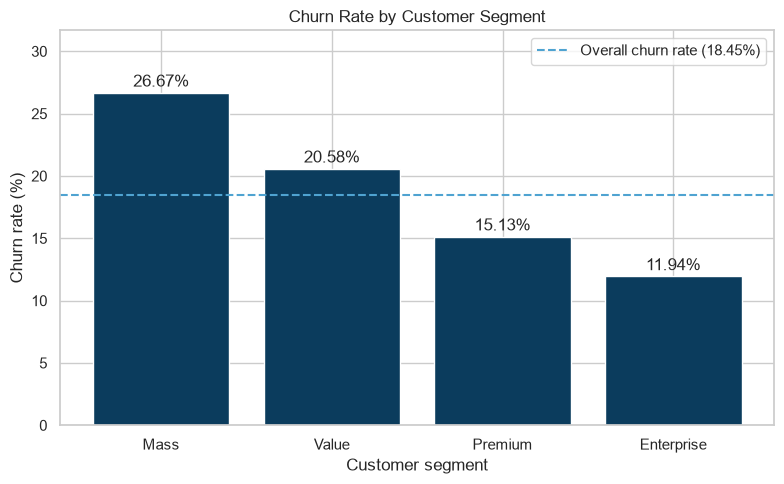

In [60]:
segment_summary = pd.crosstab(customers["customer_segment"], customers["customer_status"])
segment_summary["total"] = segment_summary["Active"] + segment_summary["Churned"]
segment_summary["churn_rate_%"] = (segment_summary["Churned"] / segment_summary["total"] * 100).round(2)
segment_summary = segment_summary.sort_values("churn_rate_%", ascending=False)
print(segment_summary)

plt.figure(figsize=(8, 5))
plt.bar(segment_summary.index, segment_summary["churn_rate_%"], color="#0B3C5D")
for i in range(len(segment_summary)):
    plt.text(i, segment_summary["churn_rate_%"].values[i] + 0.5, str(segment_summary["churn_rate_%"].values[i]) + "%", ha="center", fontsize=12)
plt.axhline(churn_rate, color="#4FA3D1", linestyle="--", label="Overall churn rate (" + str(round(churn_rate, 2)) + "%)")
plt.ylim(0, segment_summary["churn_rate_%"].max() + 5)
plt.title("Churn Rate by Customer Segment")
plt.xlabel("Customer segment")
plt.ylabel("Churn rate (%)")
plt.legend()
plt.tight_layout()
plt.savefig("chart5_churn_by_segment.png", dpi=150)
plt.show()

### Observation
Churn is highest in the Mass segment (26.67%) and lowest in the Enterprise segment (11.94%), with Value (20.58%) and Premium (15.13%) in between. Mass and Value customers churn above the overall rate of 18.45%, while Premium and Enterprise customers churn below it. Mass customers are the most price-sensitive and have the weakest ties to the company, whereas Premium and Enterprise customers usually use more services and are more likely to stay. Retention efforts should therefore focus most on the Mass and Value segments, which together contain 2,057 of the 3,506 churned customers.

## Chart 6 – Top 10 States by Churned Customers

                churned  total_customers  churn_rate_%
state_name                                            
Maharashtra         305             1876         16.26
Uttar Pradesh       285             1657         17.20
Tamil Nadu          280             1501         18.65
Rajasthan           244             1336         18.26
Karnataka           222             1164         19.07
Gujarat             191             1130         16.90
Madhya Pradesh      182              981         18.55
Kerala              162              861         18.82
Andhra Pradesh      160              832         19.23
West Bengal         157              817         19.22


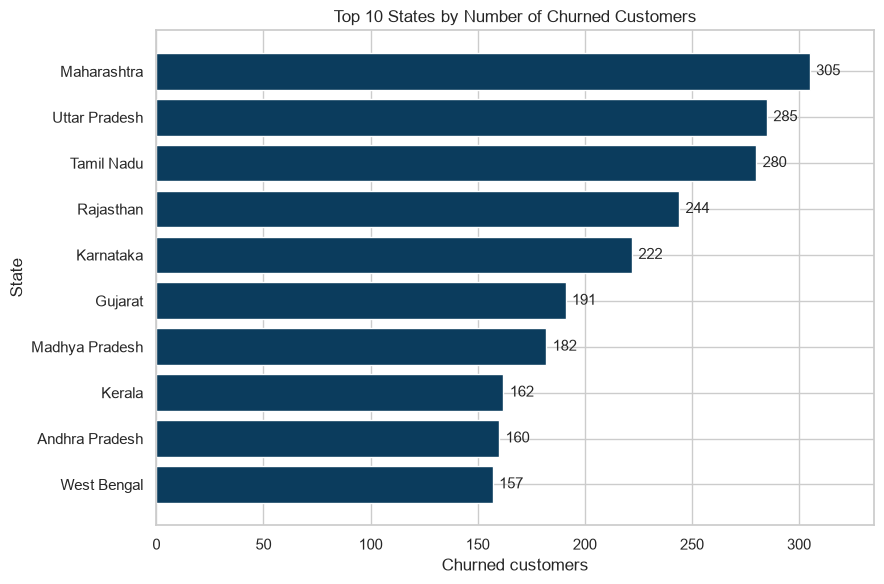

In [61]:
# add the state name to each customer
data = customers.merge(states[["state_id", "state_name"]], on="state_id", how="left")

churned_data = data[data["customer_status"] == "Churned"]
top_states = churned_data["state_name"].value_counts().head(10)

# table with total customers and churn rate for the same states
state_total = data["state_name"].value_counts()
table = pd.DataFrame({"churned": top_states, "total_customers": state_total[top_states.index]})
table["churn_rate_%"] = (table["churned"] / table["total_customers"] * 100).round(2)
print(table)

# sort so the biggest bar is at the top of the chart
top_states = top_states.sort_values()

plt.figure(figsize=(9, 6))
plt.barh(top_states.index, top_states.values, color="#0B3C5D")
for i in range(len(top_states)):
    plt.text(top_states.values[i] + 3, i, str(top_states.values[i]), va="center", fontsize=11)
plt.xlim(0, top_states.max() + 30)
plt.title("Top 10 States by Number of Churned Customers")
plt.xlabel("Churned customers")
plt.ylabel("State")
plt.tight_layout()
plt.savefig("chart6_top_states.png", dpi=150)
plt.show()

### Observation

Maharashtra has the most churned customers (305), followed by Uttar Pradesh (285) and Tamil Nadu (280). However, these are also the states with the most customers overall, and their churn rates (16% to 19%) are close to the overall rate of 18.45%. This suggests that the high counts are mainly due to the large customer base in these states and not because customers there are especially likely to leave. The business should therefore treat these states as the biggest in absolute churn volume, but look at churn rate as well when deciding where service problems may exist.


## Chart 7 – Average Data Usage by City Tier

city_tier
Metro     35.99
Tier-2    26.53
Tier-3    18.36
Name: data_gb_used, dtype: float64
Overall average: 26.83


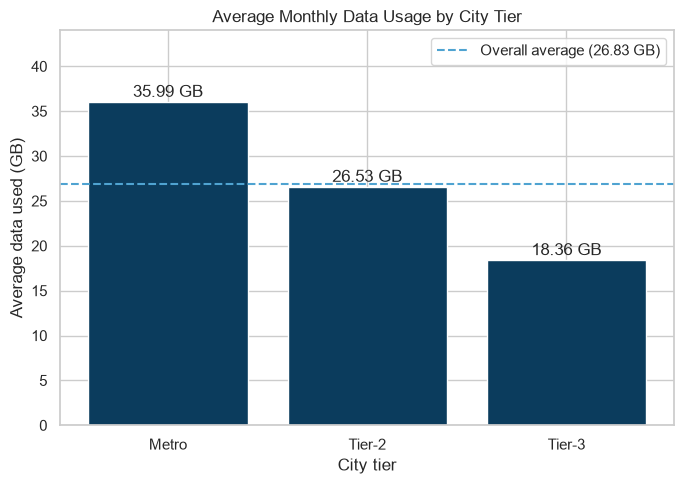

In [62]:
# add the city tier to every usage record
usage_city = usage_data.merge(customers[["customer_id", "city_tier"]], on="customer_id", how="left")

avg_usage = usage_city.groupby("city_tier")["data_gb_used"].mean().round(2).sort_values(ascending=False)
overall_avg = usage_data["data_gb_used"].mean()
print(avg_usage)
print("Overall average:", round(overall_avg, 2))

plt.figure(figsize=(7, 5))
plt.bar(avg_usage.index, avg_usage.values, color="#0B3C5D")
for i in range(len(avg_usage)):
    plt.text(i, avg_usage.values[i] + 0.6, str(avg_usage.values[i]) + " GB", ha="center", fontsize=12)
plt.axhline(overall_avg, color="#4FA3D1", linestyle="--", label="Overall average (" + str(round(overall_avg, 2)) + " GB)")
plt.ylim(0, avg_usage.max() + 8)
plt.title("Average Monthly Data Usage by City Tier")
plt.xlabel("City tier")
plt.ylabel("Average data used (GB)")
plt.legend()
plt.tight_layout()
plt.savefig("chart7_usage_by_city_tier.png", dpi=150)
plt.show()

### Observation
Data usage falls steadily with the city tier: Metro customers use 35.99 GB per month on average, Tier-2 customers use 26.53 GB and Tier-3 customers use 18.36 GB. Metro customers use almost twice as much data as Tier-3 customers. This likely reflects better network infrastructure, higher smartphone and streaming use, and higher incomes in metro cities. Data-heavy plans and network upgrades matter most in Metro areas, while Tier-3 customers may respond better to affordable plans with smaller data allowances. These averages use the cleaned data, where extreme usage values were already replaced in Phase 1.

## Chart 8 – ARPU Distribution

Active subscriptions: 17017
count    17017.0
mean       883.0
std       1395.0
min         99.0
25%        300.0
50%        499.0
75%        999.0
max       8333.0
Name: monthly_charge_inr, dtype: float64
Mean: 883 | Median: 499


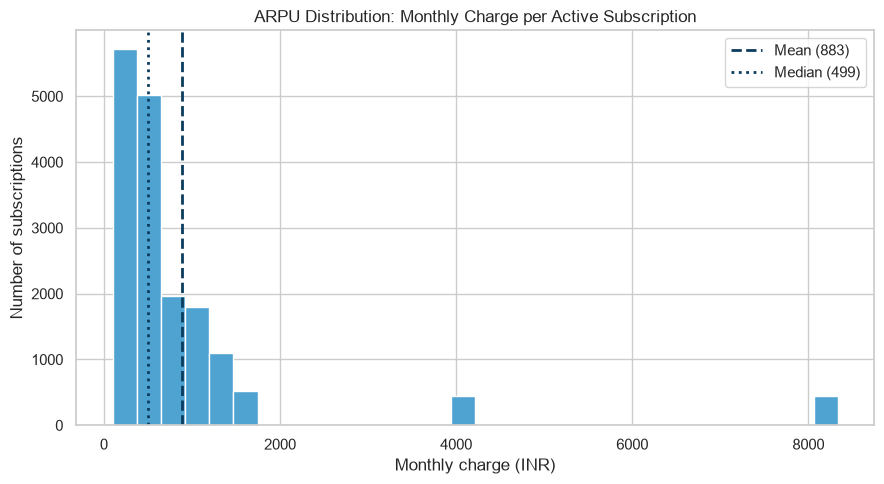

In [63]:
# monthly charge of every active subscription
active_subs = subscriptions[subscriptions["subscription_status"] == "Active"]
charges = active_subs["monthly_charge_inr"]

print("Active subscriptions:", len(charges))
print(charges.describe().round(0))
print("Mean:", round(charges.mean()), "| Median:", round(charges.median()))

plt.figure(figsize=(9, 5))
plt.hist(charges, bins=30, color="#4FA3D1", edgecolor="white")
plt.axvline(charges.mean(), color="#0B3C5D", linestyle="--", linewidth=2, label="Mean (" + str(round(charges.mean())) + ")")
plt.axvline(charges.median(), color="#0B3C5D", linestyle=":", linewidth=2, label="Median (" + str(round(charges.median())) + ")")
plt.title("ARPU Distribution: Monthly Charge per Active Subscription")
plt.xlabel("Monthly charge (INR)")
plt.ylabel("Number of subscriptions")
plt.legend()
plt.tight_layout()
plt.savefig("chart8_arpu_distribution.png", dpi=150)
plt.show()

### Observation
The monthly charge distribution is strongly right-skewed. Most active subscriptions pay between ₹99 and about ₹1,500 per month, and the median charge is ₹499. The mean (₹883) is much higher than the median because a small group of roughly 890 subscriptions (about 5%) pay very high charges of around ₹4,166 and ₹8,333. This means the average revenue per subscriber is pulled up by a few high-value plans, and the typical customer pays much less than the average suggests. Because these high-value subscriptions contribute a large share of revenue, losing them to churn would hurt far more than losing a typical customer.

## Chart 9 – Network Quality vs Churn

customer_status
Active     2.36
Churned    2.59
Name: avg_dropped_call_rate, dtype: float64
customer_status    Active  Churned  total  churn_rate_%
call_group                                             
Low (<1.5%)          3527      599   4126         14.52
Medium (1.5-2.5%)    5404     1103   6507         16.95
High (2.5-3.5%)      4149     1070   5219         20.50
Very high (3.5%+)    2414      734   3148         23.32


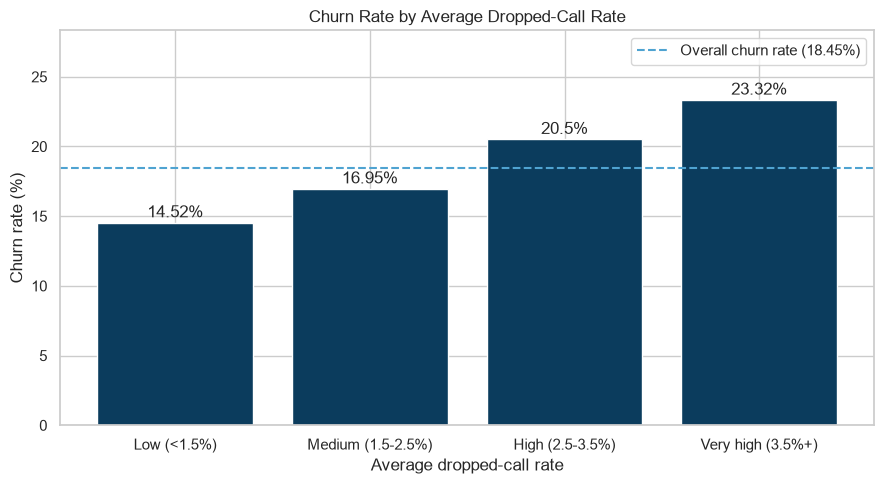

In [64]:
# average dropped-call rate of each customer (they have 3 months of records)
avg_calls = network_quality.groupby("customer_id")["dropped_call_rate_pct"].mean().reset_index(name="avg_dropped_call_rate")
data = customers.merge(avg_calls, on="customer_id", how="left")

# average dropped-call rate of churned vs active customers
print(data.groupby("customer_status")["avg_dropped_call_rate"].mean().round(2))

# group customers by dropped-call rate
data["call_group"] = pd.cut(data["avg_dropped_call_rate"], bins=[0, 1.5, 2.5, 3.5, 100],
                            labels=["Low (<1.5%)", "Medium (1.5-2.5%)", "High (2.5-3.5%)", "Very high (3.5%+)"])

summary9 = pd.crosstab(data["call_group"], data["customer_status"])
summary9["total"] = summary9["Active"] + summary9["Churned"]
summary9["churn_rate_%"] = (summary9["Churned"] / summary9["total"] * 100).round(2)
print(summary9)

plt.figure(figsize=(9, 5))
plt.bar(summary9.index.astype(str), summary9["churn_rate_%"], color="#0B3C5D")
for i in range(len(summary9)):
    plt.text(i, summary9["churn_rate_%"].values[i] + 0.4, str(summary9["churn_rate_%"].values[i]) + "%", ha="center", fontsize=12)
plt.axhline(churn_rate, color="#4FA3D1", linestyle="--", label="Overall churn rate (" + str(round(churn_rate, 2)) + "%)")
plt.ylim(0, summary9["churn_rate_%"].max() + 5)
plt.title("Churn Rate by Average Dropped-Call Rate")
plt.xlabel("Average dropped-call rate")
plt.ylabel("Churn rate (%)")
plt.legend()
plt.tight_layout()
plt.savefig("chart9_network_vs_churn.png", dpi=150)
plt.show()

### Observation
Churn increases steadily as the dropped-call rate rises: 14.52% for customers with a low dropped-call rate, 16.95% for medium, 20.50% for high and 23.32% for very high. Churned customers also had a higher average dropped-call rate than active customers (2.59% compared with 2.36%). Customers who experience poor call quality are more likely to leave, so network improvements in areas with high dropped-call rates could help retention. The relationship is clear but moderate, so network quality is one factor among several, and the data shows an association, not proof of cause.

## Chart 10 – Retention Campaign Outcomes

response
Accepted       2982
Declined       1877
No Response    1616
Name: count, dtype: int64
Overall retained share: 82.42 %
retained_flag   No   Yes  total  retained_%
response                                   
Accepted       393  2589   2982       86.82
Declined       391  1486   1877       79.17
No Response    354  1262   1616       78.09


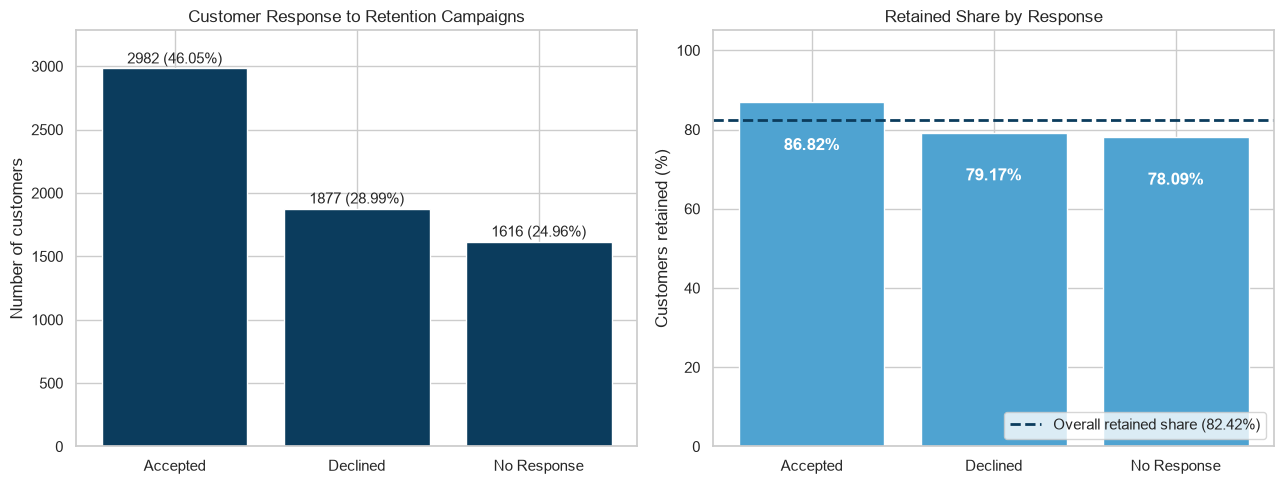

In [65]:
# how customers responded to the campaigns
response_counts = retention["response"].value_counts()
response_pct = (response_counts / len(retention) * 100).round(2)
retained_share = (retention["retained_flag"] == "Yes").mean() * 100
print(response_counts)
print("Overall retained share:", round(retained_share, 2), "%")

# retained share for each type of response
by_response = pd.crosstab(retention["response"], retention["retained_flag"])
by_response["total"] = by_response["Yes"] + by_response["No"]
by_response["retained_%"] = (by_response["Yes"] / by_response["total"] * 100).round(2)
by_response = by_response.loc[["Accepted", "Declined", "No Response"]]
print(by_response)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# left: how many customers gave each response
axes[0].bar(response_counts.index, response_counts.values, color="#0B3C5D")
for i in range(len(response_counts)):
    axes[0].text(i, response_counts.values[i] + 40, str(response_counts.values[i]) + " (" + str(response_pct.values[i]) + "%)", ha="center", fontsize=11)
axes[0].set_ylim(0, response_counts.max() + 300)
axes[0].set_title("Customer Response to Retention Campaigns")
axes[0].set_ylabel("Number of customers")

# right: share of customers retained for each response
axes[1].bar(by_response.index, by_response["retained_%"], color="#4FA3D1")
for i in range(len(by_response)):
    axes[1].text(i, by_response["retained_%"].values[i] - 12, str(by_response["retained_%"].values[i]) + "%", ha="center", fontsize=12, color="white", fontweight="bold")
axes[1].axhline(retained_share, color="#0B3C5D", linestyle="--", linewidth=2, label="Overall retained share (" + str(round(retained_share, 2)) + "%)")
axes[1].set_ylim(0, 105)
axes[1].set_title("Retained Share by Response")
axes[1].set_ylabel("Customers retained (%)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig("chart10_retention_outcomes.png", dpi=150)
plt.show()

### Observation
Of the 6,475 customers contacted, 46.05% accepted the retention offer, 28.99% declined and 24.96% did not respond. Overall, 82.42% of contacted customers were retained. Customers who accepted an offer were retained at 86.82%, which is about 8 percentage points higher than those who declined (79.17%) or did not respond (78.09%). This suggests the offers help, but the data has no comparison group of customers who were not contacted, so the true effect of the campaigns cannot be measured. Since nearly half of the customers accept offers, further analysis of which offers and channels work best could improve results.

## Key Insights

**Overall picture**
- 3,506 of 19,000 customers (18.45%) have churned, so almost one in five customers has already been lost.

**Who is most likely to churn**
- **New customers:** churn is 74.90% in the first 3 months and falls to 8.33% after 3 years, so the first year is the riskiest period.
- **Monthly-plan customers:** they churn at 22.54%, about three times the rate of annual-plan customers (7.17%).
- **Mass and Value segments:** Mass churns at 26.67% and Value at 20.58%, compared with 11.94% for Enterprise.

**What is linked to churn**
- **Unresolved complaints:** churn rises from 15.11% (no unresolved complaints) to 48.32% (three or more).
- **Network quality:** churn rises from 14.52% for customers with low dropped-call rates to 23.32% for those with very high rates.

**Geography, usage and revenue**
- Maharashtra, Uttar Pradesh and Tamil Nadu have the most churned customers, but their churn rates (16% to 19%) are close to the overall rate, so the high counts mainly reflect large customer bases.
- Data usage falls with city tier: Metro 35.99 GB, Tier-2 26.53 GB and Tier-3 18.36 GB per month.
- The median monthly charge is ₹499, but the mean is ₹883, because roughly 5% of active subscriptions pay very high charges (₹4,166 and ₹8,333).

**Retention campaigns**
- 46.05% of contacted customers accepted an offer, and 82.42% of all contacted customers were retained. Customers who accepted were retained at 86.82%, compared with about 78% to 79% for those who declined or did not respond.

**Recommendations**
1. Focus retention efforts on customers in their first year, especially those on monthly plans.
2. Offer incentives to move monthly customers to annual plans.
3. Resolve complaints quickly, with priority for customers who have raised more than one.
4. Improve network quality in areas with high dropped-call rates.
5. Target Mass and Value customers with retention offers, and prioritise high-value subscriptions to protect revenue.

